# Exploratory Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/home/jawad/my_jupyter_env/Data_Science_Projects/House_price_analysis/clean_data.csv")
df.head()

,Unnamed: 0,Area_sqft,Bedrooms,Bathrooms,Floors,Age_years,Location,Garage,Crime_Rate,Distance_Center_km,Price_PKR
0,0,1913.0,3,1,2,29,Urban,Yes,43.5,5.3,10153438.0
1,1,1747.0,3,2,1,11,Suburban,No,37.8,8.1,9212818.0
2,2,2924.0,7,5,1,2,Urban,No,33.3,6.5,13264421.0
3,3,1449.0,5,3,1,25,Suburban,Yes,27.8,2.3,9416110.0
4,4,833.0,2,2,1,24,Suburban,No,31.7,3.3,4336305.0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10005 entries, 0 to 10004
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          10005 non-null  int64  
 1   Area_sqft           10005 non-null  float64
 2   Bedrooms            10005 non-null  int64  
 3   Bathrooms           10005 non-null  int64  
 4   Floors              10005 non-null  int64  
 5   Age_years           10005 non-null  int64  
 6   Location            10005 non-null  str    
 7   Garage              10005 non-null  str    
 8   Crime_Rate          10005 non-null  float64
 9   Distance_Center_km  10005 non-null  float64
 10  Price_PKR           9965 non-null   float64
dtypes: float64(4), int64(5), str(2)
memory usage: 859.9 KB


In [4]:
# Average house area in square feet
avg_house_sqft = df["Area_sqft"].mean()
print("Average House area of square feet : ",avg_house_sqft)

# maximum area in  the area sqft column
max_area_sqft  = df["Area_sqft"].max()
print("maximum area in sqft : ",max_area_sqft)

# minimum area in the area sqft 
min_area_sqft = df["Area_sqft"].min()
print("minimum area in sqft : ",min_area_sqft)
print("--"*34)


# average of bedrooms 
avg_bedrooms = df["Bedrooms"].mean()
print("Average bedrooms : ",avg_bedrooms.__floor__())

# maximum bedrooms 
max_bedrooms = df["Bedrooms"].max()
print("Maximum number of bedrooms : ",max_bedrooms)

# mininum bedrooms 
min_bedrooms = df["Bedrooms"].min()
print("Minimum number of bedrooms : ",min_bedrooms)

# most common number of bedrooms.
common_number_bedrooms = df["Bedrooms"].mode()[0]
print("Most common number of bedrooms : ",common_number_bedrooms)
print("--"*34)

# average age of house 
avg_age_of_house = df["Age_years"].mean()
print("Average age of the house : ",avg_age_of_house.__floor__())

# min age of house 
min_age_house  = df["Age_years"].min()
print("Minimum age of the house : ",min_age_house)

# Max age of house 
max_age_house = df["Age_years"].max()
print("Maximum age of house : ",max_age_house)
print("--"*34)

# average of house price
avg_house_price = df["Price_PKR"].mean()
print("Average price of house in Pkr : ",avg_house_price)

# median of house price in pkr 
median_house_price = df["Price_PKR"].median()
print("Median of house price in Pkr : ",median_house_price)

# minimum price of house in pkr 
min_price_house = df["Price_PKR"].min()
print("minimum price of house in pkr : ",min_price_house)

# maximum price of house in pkr 
max_house_price = df["Price_PKR"].max()
print("Maximum house price in PKr : ",max_house_price)


Average House area of square feet :  1601.1175412293853
maximum area in sqft :  3426.0
minimum area in sqft :  1.0
--------------------------------------------------------------------
Average bedrooms :  3
Maximum number of bedrooms :  8
Minimum number of bedrooms :  1
Most common number of bedrooms :  3
--------------------------------------------------------------------
Average age of the house :  30
Minimum age of the house :  1
Maximum age of house :  60
--------------------------------------------------------------------
Average price of house in Pkr :  7793422.127646764
Median of house price in Pkr :  7312805.0
minimum price of house in pkr :  700000.0
Maximum house price in PKr :  15632108.5


In [5]:
# std of house price 
price = df["Price_PKR"].dropna()
mean = sum(price)/len(price)
deviation = price - mean
squared_deviation = deviation ** 2
varience = sum(squared_deviation)/(len(price-1))
std_house_price = np.sqrt(varience)
print("Standard deviation of house price : ",std_house_price)


# 25th, 50th, and 75th percentiles of Price_PKR.
Q1 = np.percentile(price,0.25)
print("25th percentile of house price pkr : ",Q1)
Q2 = np.percentile(price,0.50)
print("50th percentile of the house price pkr : ",Q2)
Q3 = np.percentile(price,0.75)
print("75th percentile of the house price pkr : ",Q3)


Standard deviation of house price :  3164209.19818625
25th percentile of house price pkr :  1125985.24
50th percentile of the house price pkr :  1598758.22
75th percentile of the house price pkr :  1859499.85


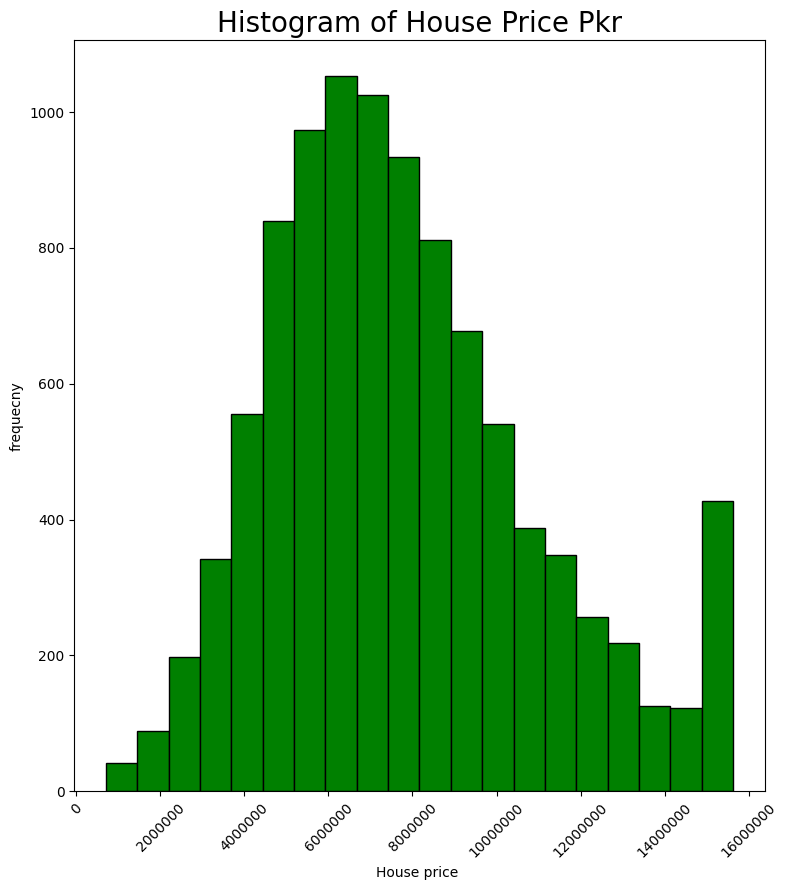

In [6]:
# histogram of Price_PKR and determine whether its distribution is skewed.
plt.figure(figsize=(8,9))
plt.hist(df["Price_PKR"],bins=20,edgecolor = "black",color = "green")
plt.title("Histogram of House Price Pkr",fontsize = 20)
plt.xlabel("House price ")
plt.ylabel("frequecny")
plt.ticklabel_format(style="plain", axis="x")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("histograrm_of_house_price_in_pkr.png",dpi = 300,bbox_inches = "tight")
plt.show()

# the distribution are right skewed 

In [51]:
# Realation between area sqft and price pkr 
real_between_area_and_price = df["Area_sqft"].corr(df["Price_PKR"])
print("Realation between area Sqft and Price pkr : ",real_between_area_and_price)
# the area sqft and the price pkr have a strong relationship 

# calculating the average price of 2,3,4 and 5 bedrooms
avg_price = df.groupby("Bedrooms")["Price_PKR"].mean()
avg_price = avg_price.loc[[2,3,4,5]]
print("Average price of 2,3,4 and 5 bedrooms : ",avg_price.apply(lambda X: f"{X:,.0f}"))
print("--"*34)

# analyzig the realtionship between bathrooms and price pkr
relation = df["Bathrooms"].corr(df["Price_PKR"])
print("realtion ship between bathrooms and price pkr : ",relation)
print("--"*34)


# comparing average house price across the different floors value 
avg_pricee = df.groupby("Floors")["Price_PKR"].mean()
avg_pricee = avg_pricee.loc[[1,2,3]]
print("Average house price across different number of floors : ",avg_pricee.apply(lambda X : f"{X:,.0f}"))



Realation between area Sqft and Price pkr :  0.8702456507535957
Average price of 2,3,4 and 5 bedrooms :  Bedrooms
2     6,000,124
3     7,369,145
4     8,927,647
5    10,797,887
Name: Price_PKR, dtype: str
--------------------------------------------------------------------
realtion ship between bathrooms and price pkr :  0.7436973902576649
--------------------------------------------------------------------
Average house price across different number of floors :  Floors
1    7,649,751
2    7,869,711
3    7,868,076
Name: Price_PKR, dtype: str


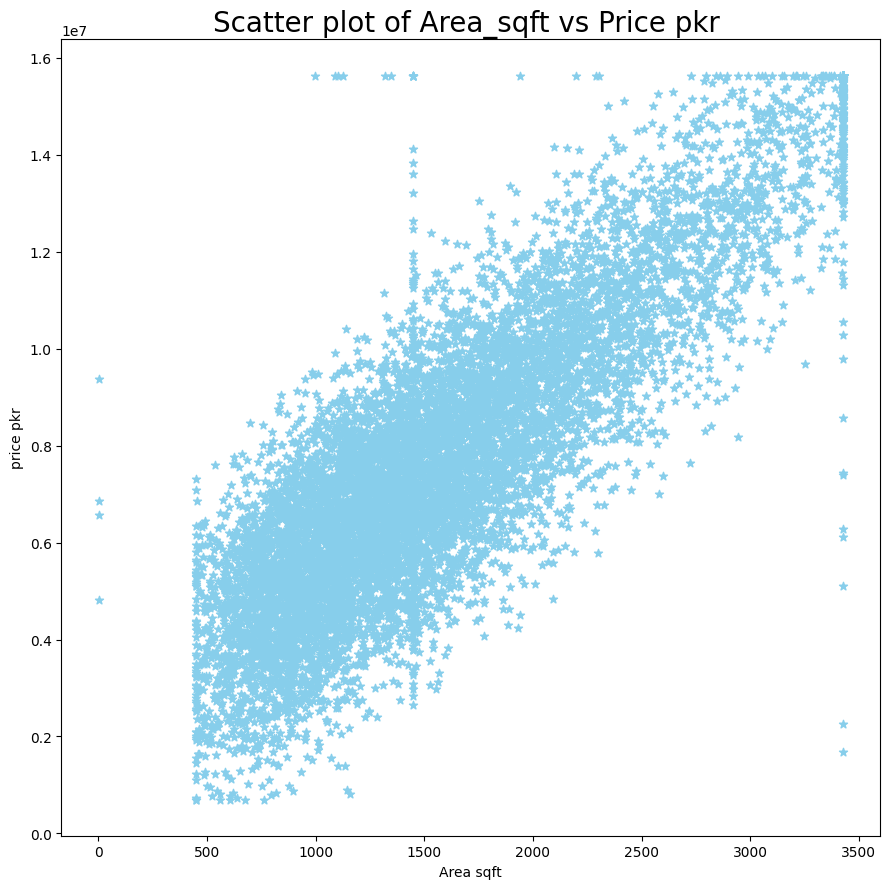

In [8]:
# scatter plot of area sqft and price pkr 
plt.figure(figsize=(9,9))
plt.scatter(df["Area_sqft"],df["Price_PKR"],color = "skyblue",marker = "*")
plt.title("Scatter plot of Area_sqft vs Price pkr ",fontsize = 20)
plt.xlabel("Area sqft")
plt.ylabel("price pkr")
plt.tight_layout()
plt.savefig("Area_sqft_VS_price_Pkr.png",dpi = 300,bbox_inches = "tight")
plt.show()

In [9]:
# realtionship between age of the house and price of the house 
relation_BW_age_price = df["Age_years"].corr(df["Price_PKR"])
print("Relationship between the Age of the house and the price of the house : ",relation_BW_age_price)
# strong negative linear relationship.


# compare the price of the newer house with older house 
newer_house = df[df["Age_years"] < 10]
older_house = df[df["Age_years"] >= 10]
avg_newer_house = newer_house["Price_PKR"].mean()
avg_older_house = older_house["Price_PKR"].mean()
print("Average price of newer house  : ",avg_newer_house)
print("Average price of older house : ",avg_older_house)

Relationship between the Age of the house and the price of the house :  -0.15299944000754848
Average price of newer house  :  8458716.307570977
Average price of older house :  7667587.846599045


In [10]:
# analyzing the relationship between the crime rate and price pkr
rela_between_Crime_price  = df["Crime_Rate"].corr(df["Price_PKR"])
print("Relation between Crime rate and price pkr : ",rela_between_Crime_price)
# strong negative liner realtionship between crime rate and house price 

# analyzing the relationship between distance center km and price pkr  
rel_bw_dist_price = df["Distance_Center_km"].corr(df["Price_PKR"])
print("Realtion between Distance Center km and Price pkr :",rel_bw_dist_price)

Relation between Crime rate and price pkr :  -0.03913683546290091
Realtion between Distance Center km and Price pkr : -0.04343937446084419


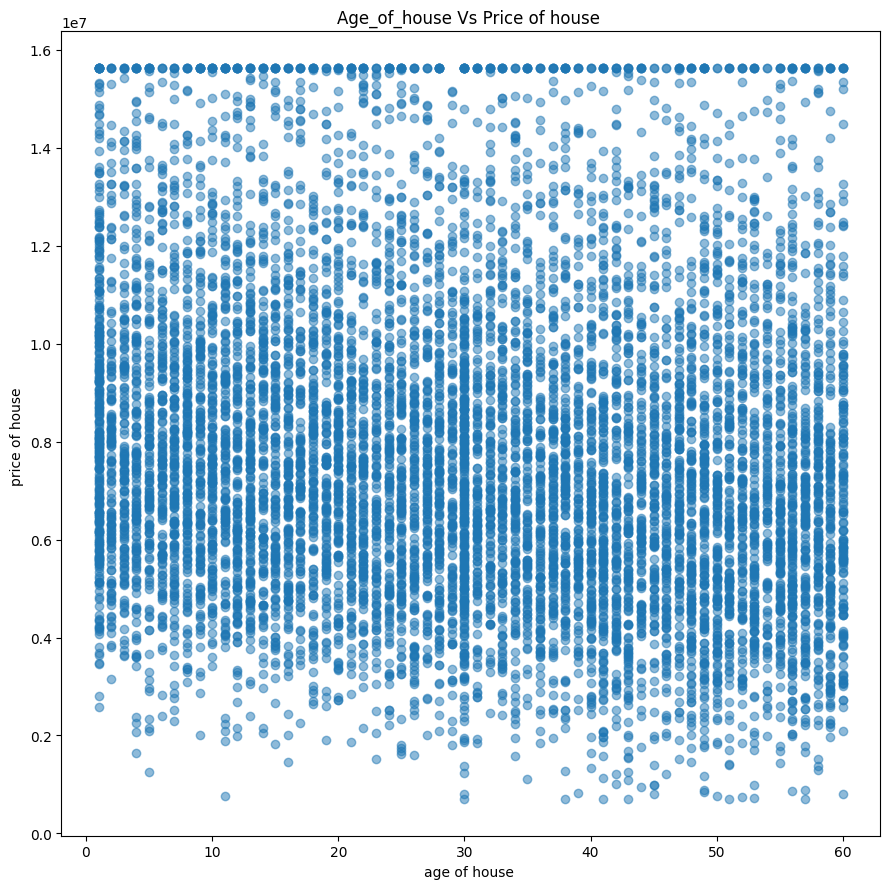

In [11]:
# creating scatter plot showinf AGe of the house versus price of the house 
plt.figure(figsize=(9,9))
plt.scatter(df["Age_years"],df["Price_PKR"],marker = "o",alpha=0.5)
plt.title("Age_of_house Vs Price of house ")
plt.xlabel("age of house ")
plt.ylabel("price of house ")
plt.tight_layout()
plt.savefig("Age_of_house_Vs_Price_of_house.png",dpi =300,bbox_inches = "tight")
plt.show()

In [12]:
# average house price for each location
avg_house_price_location = df.groupby("Location")["Price_PKR"].median()
print("Average house price for each location : ",avg_house_price_location)

# location with highest average house price 
loca_high_avg_price = avg_house_price_location.idxmax()
print("\nLocation with highest average house price : ",loca_high_avg_price)

# calculating the number of house in each location 
count_house_in_each_location = df.groupby("Location")["Price_PKR"].count()
print("\nNumber of houses in each location : ",count_house_in_each_location)

# average area of houses in each location 
avg_area_of_house = df.groupby("Location")["Area_sqft"].mean()
print("\nAverage house area in each location : ",avg_area_of_house)

Average house price for each location :  Location
Rural       6132680.0
Suburban    7047242.5
Urban       8136718.0
Name: Price_PKR, dtype: float64

Location with highest average house price :  Urban

Number of houses in each location :  Location
Rural       2026
Suburban    3772
Urban       4167
Name: Price_PKR, dtype: int64

Average house area in each location :  Location
Rural       1592.764619
Suburban    1610.788736
Urban       1596.442693
Name: Area_sqft, dtype: float64


In [13]:
# calculating the average price for each bedrooms categories .
bedrooms_category_price = df.groupby("Bedrooms")["Price_PKR"].mean()
print("Average price for each bedrooms category : ",bedrooms_category_price.apply(lambda x :f"{x:,.0f}"))

# Average house price fore each floor category
avg_price_floor_category = df.groupby("Floors")["Price_PKR"].mean()
print("\nAverage house price fore each floor  category : ",avg_price_floor_category.apply(lambda x : f"{x:,.0f}"))


Average price for each bedrooms category :  Bedrooms
1     4,865,128
2     6,000,124
3     7,369,145
4     8,927,647
5    10,797,887
6    12,526,925
7    14,349,446
8    15,444,225
Name: Price_PKR, dtype: str

Average house price fore each floor  category :  Floors
1    7,649,751
2    7,869,711
3    7,868,076
Name: Price_PKR, dtype: str


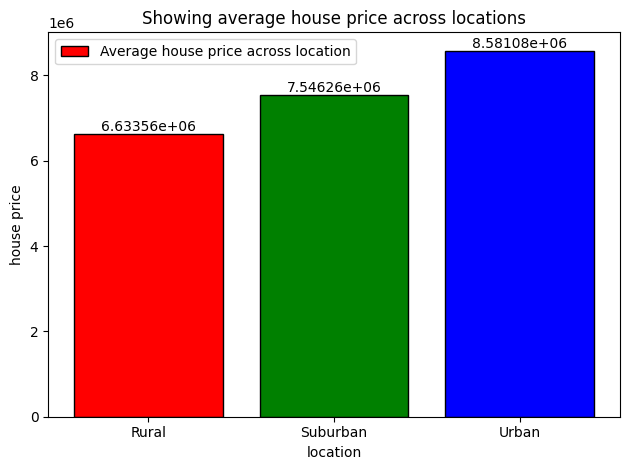

In [14]:
# creating a bar chart showing average house price across locations .
average_house_price_across_location = df.groupby("Location")["Price_PKR"].mean()
avg_house_across = average_house_price_across_location.apply(lambda x : f"{x:,.0f}")
plt.Figure(figsize=(9,6))
bar = plt.bar(average_house_price_across_location.index,average_house_price_across_location.values,label="Average house price across location",edgecolor = "black",color = ["red","green","blue"])
plt.bar_label(bar)
plt.title("Showing average house price across locations")
plt.xlabel("location")
plt.ylabel("house price")
plt.tight_layout()
plt.legend()
plt.savefig("barchart_of_house_price_across_location.png",dpi=300,bbox_inches="tight")
plt.show()


In [15]:
# comparing the mean and median of house price and what the diffrence tells us .
mean_of_house_price = df["Price_PKR"].mean()
print("mean of the house price : ",mean_of_house_price)
median_house_price = df["Price_PKR"].median()
print("median of the house price :",median_house_price)  # median are not affected to much with the outlier and mean are affected to much with the outlier .
skeweness_house_price = df["Price_PKR"].skew()
print("skeweness of house price : ",skeweness_house_price*100)


mean of the house price :  7793422.127646764
median of the house price : 7312805.0
skeweness of house price :  62.89124354685536


In [16]:
# calculating the IQR of house price 
price = df["Price_PKR"].dropna()
Q1 = np.quantile(price,0.25)
Q3 = np.quantile(price,0.75)
IQR = Q3 - Q1
print("Inter quartile range of the house price : ",IQR)


# calculating the correlation matrix for all numerical columns 
correlation_matrix = df.corr(numeric_only=True)
correlation_matrix

Inter quartile range of the house price :  4044545.0


,Unnamed: 0,Area_sqft,Bedrooms,Bathrooms,Floors,Age_years,Crime_Rate,Distance_Center_km,Price_PKR
Unnamed: 0,1.000000,-0.003783,-0.000840,0.001482,0.010978,-0.015049,-0.008698,0.007673,-0.004524
Area_sqft,-0.003783,1.000000,0.852027,0.769060,0.001845,-0.008883,0.020725,0.007157,0.870246
Bedrooms,-0.000840,0.852027,1.000000,0.881324,0.001381,-0.002872,0.019629,0.005941,0.810473
Bathrooms,0.001482,0.769060,0.881324,1.000000,0.010490,-0.000054,0.022959,0.005076,0.743697
Floors,0.010978,0.001845,0.001381,0.010490,1.000000,0.004110,-0.001095,-0.007510,0.029169
Age_years,-0.015049,-0.008883,-0.002872,-0.000054,0.004110,1.000000,-0.005009,-0.001593,-0.152999
Crime_Rate,-0.008698,0.020725,0.019629,0.022959,-0.001095,-0.005009,1.000000,0.017054,-0.039137
Distance_Center_km,0.007673,0.007157,0.005941,0.005076,-0.007510,-0.001593,0.017054,1.000000,-0.043439
Price_PKR,-0.004524,0.870246,0.810473,0.743697,0.029169,-0.152999,-0.039137,-0.043439,1.000000


In [17]:
price_corr = correlation_matrix["Price_PKR"].drop("Price_PKR")
strongest_postive_corr = price_corr.idxmax()
strongest_negative_corr = price_corr.idxmin()
print("Strongest positive correaltion of house price : ",strongest_postive_corr,price_corr.max()*100)
print("Strongest negative correalation of house price :",strongest_negative_corr,price_corr.min()*100)
# Area_sqft (0.870): This has the strongest positive correlation with house price
# Age_years (-0.153): This has a weak negative correlation with house price.

# calculating varience for house price 
var_house_price = np.var(df["Price_PKR"])
std_house_price = np.std(df["Price_PKR"])
print("Varience of house price  : ",var_house_price)
print("Standard deviation of house price : ",std_house_price)

Strongest positive correaltion of house price :  Area_sqft 87.02456507536004
Strongest negative correalation of house price : Age_years -15.299944000754826
Varience of house price  :  10012219849886.469
Standard deviation of house price :  3164209.1981862495


In [18]:
# identify the outliers in the house price 
price_house = df["Price_PKR"]
def detect_oulier(price_house):
    Q1 = price_house.quantile(0.25)
    Q3 = price_house.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * (IQR)
    upper_bound = Q3 + 1.5 * (IQR)
    outliers = df[(price_house< lower_bound) | (price_house > upper_bound)]
    print("Quartile one : ",Q1)
    print("Quartile third : ",Q3)
    print("Inter Quartile Range : ",IQR)
    print("Lower bound : ",lower_bound)
    print("Upper bound : ",upper_bound)
    print("Outliers : ",outliers)
    return outliers

outlier_price_PKR = detect_oulier(price_house)

Quartile one :  5520746.0
Quartile third :  9565291.0
Inter Quartile Range :  4044545.0
Lower bound :  -546071.5
Upper bound :  15632108.5
Outliers :  Empty DataFrame
Columns: [Unnamed: 0, Area_sqft, Bedrooms, Bathrooms, Floors, Age_years, Location, Garage, Crime_Rate, Distance_Center_km, Price_PKR]
Index: []


In [19]:
# calculating the kurtosis of house price 
kurtosis_price = df["Price_PKR"].kurtosis()
print("Kurtosis of house price : ",kurtosis_price)

Kurtosis of house price :  0.017411073268694732


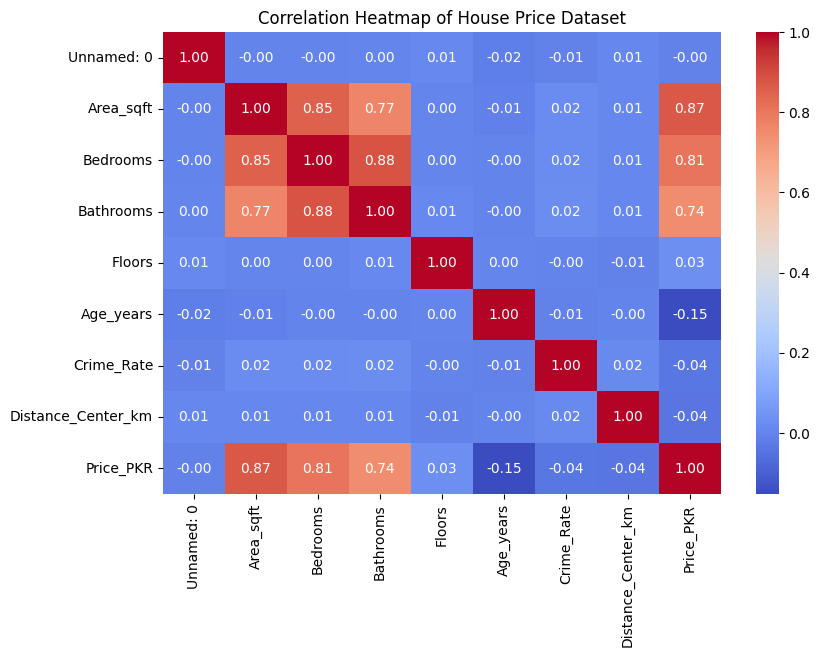

In [20]:
# correlation heatmap
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(9,6))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt = ".2f")
plt.title("Correlation Heatmap of House Price Dataset")
plt.savefig("correlation_heatmap.png",dpi =300,bbox_inches = "tight")
plt.show()


/home/jawad/my_jupyter_env/lib/python3.14/site-packages/pandas/plotting/_matplotlib/boxplot.py:62: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, **kwargs)


<Figure size 1000x600 with 0 Axes>

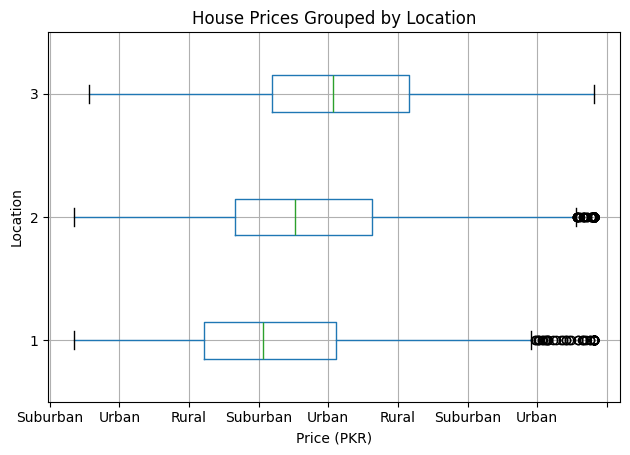

In [21]:
# creating a box plot for the price pkr grouped by city .

plt.figure(figsize=(10, 6))

df.boxplot(column="Price_PKR",by="Location",orientation = "horizontal")

plt.title("House Prices Grouped by Location")
plt.suptitle("")
plt.xlabel("Price (PKR)")
plt.ylabel("Location")
plt.tight_layout()
plt.savefig("house_price_grouped_by_city.png",dpi = 300,bbox_inches = "tight")
plt.show()


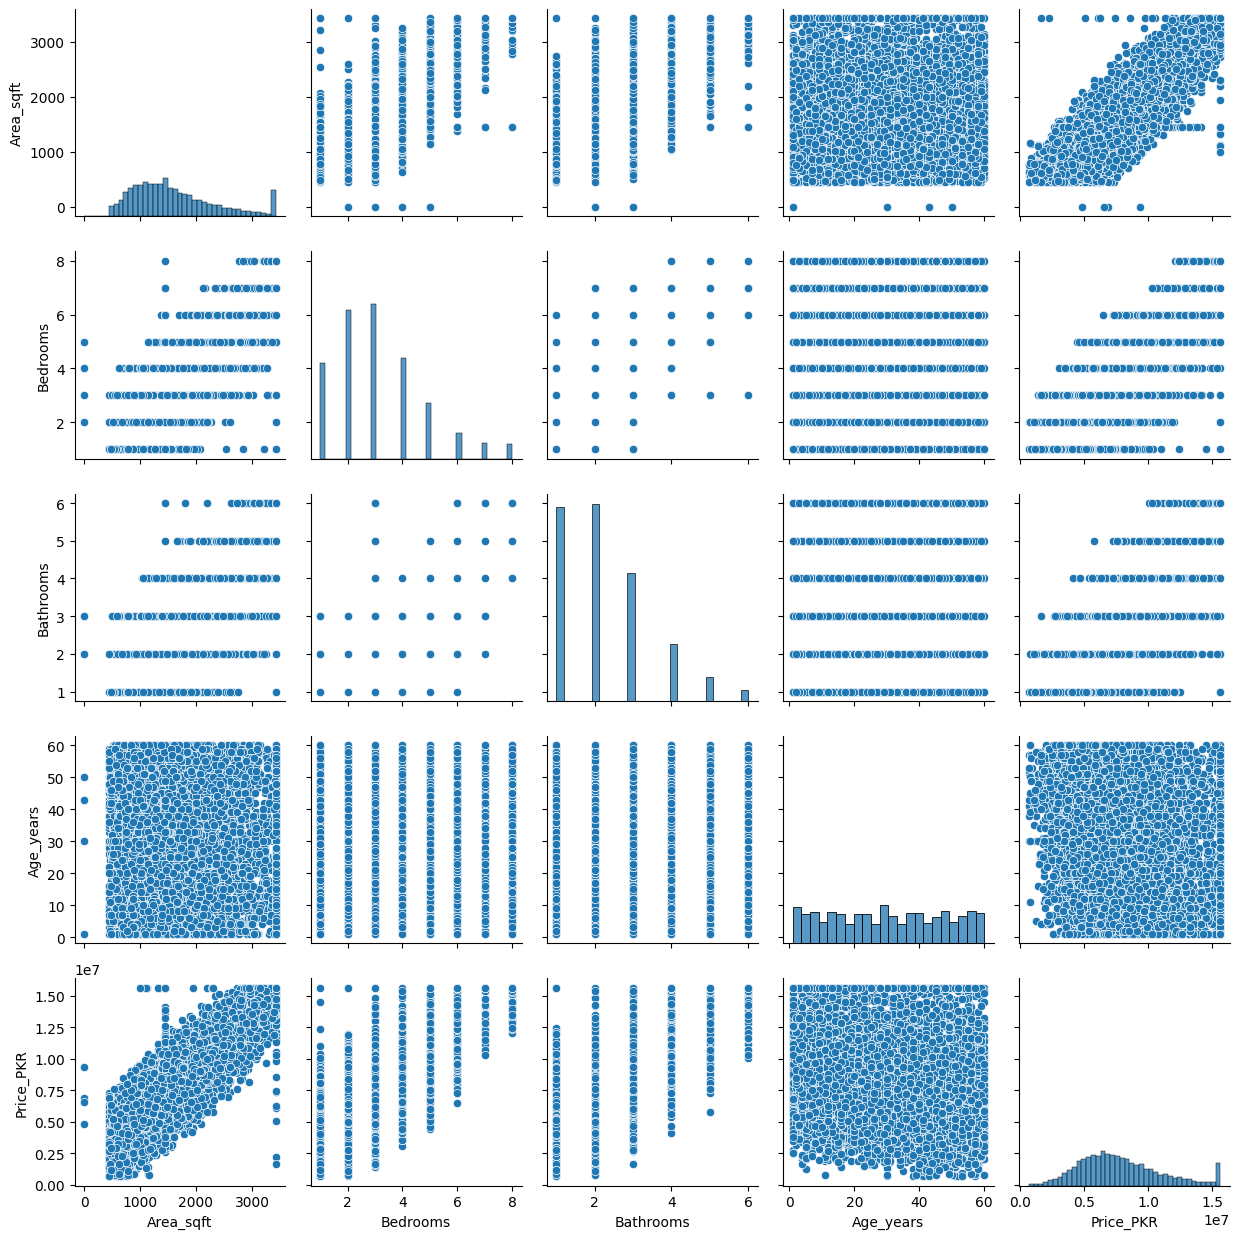

In [22]:
# creating a pair plot for the columns .
sns.pairplot(df[["Area_sqft","Bedrooms","Bathrooms","Age_years","Price_PKR"]],diag_kind="hist")
plt.tight_layout()
plt.savefig("pair_plot.png",dpi = 300,bbox_inches="tight")
plt.show()

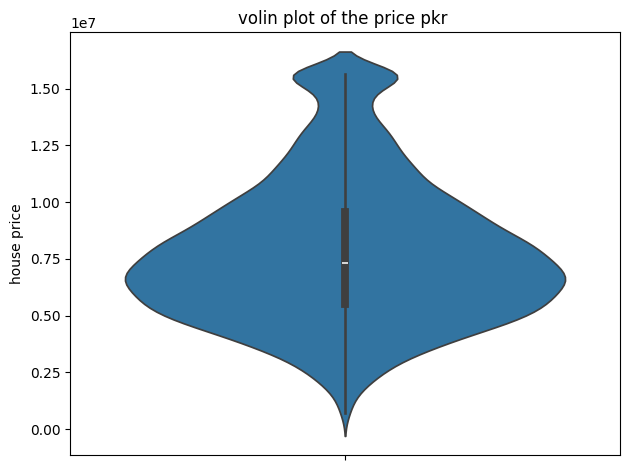

In [23]:
# creating a volin plot showing the distribution of the house price across the location .
sns.violinplot(df["Price_PKR"])
plt.title("volin plot of the price pkr ")
plt.ylabel("house price")
plt.tight_layout()
plt.savefig("volinplot_price.png",dpi = 300)
plt.show()

In [45]:
# investigating whether house price has a liner relationship with the area sqft .
relation_with_area_sqft = df["Price_PKR"].corr(df["Area_sqft"])
print("Relation : ",relation_with_area_sqft) # the price has a 87 % relation with the area sqft and it is liner.

# top ten most expensive house .
top_ten_house = df.sort_values(by ="Price_PKR",ascending = False).head(10)
top_ten_house



Relation :  0.8702456507535957


,Unnamed: 0,Area_sqft,Bedrooms,Bathrooms,Floors,Age_years,Location,Garage,Crime_Rate,Distance_Center_km,Price_PKR
594,594,3426.0,8,6,2,5,Suburban,Yes,18.7,7.8,15632108.5
9994,10109,3426.0,8,6,2,41,Suburban,Yes,37.1,6.8,15632108.5
9996,10111,3426.0,8,5,1,20,Suburban,Yes,33.8,8.4,15632108.5
6729,6786,3333.0,5,4,2,9,Urban,Yes,40.4,16.0,15632108.5
9962,10076,3426.0,8,6,1,10,Urban,Yes,52.7,5.3,15632108.5
35,35,3426.0,8,6,1,56,Suburban,Yes,53.6,5.3,15632108.5
6754,6811,3426.0,8,6,1,24,Suburban,Yes,46.2,7.5,15632108.5
9660,9767,3144.0,7,6,2,9,Suburban,No,10.4,6.9,15632108.5
9741,9851,3426.0,8,6,2,14,Suburban,Yes,50.4,11.7,15632108.5
9637,9744,3426.0,8,5,2,35,Urban,No,22.3,2.9,15632108.5


In [46]:
# characterisitcs of top ten house 
charateristics = ["Price_PKR","Location", "Area_sqft", "Bedrooms", "Bathrooms"]
print(top_ten_house[charateristics])

       Price_PKR  Location  Area_sqft  Bedrooms  Bathrooms
594   15632108.5  Suburban     3426.0         8          6
9994  15632108.5  Suburban     3426.0         8          6
9996  15632108.5  Suburban     3426.0         8          5
6729  15632108.5     Urban     3333.0         5          4
9962  15632108.5     Urban     3426.0         8          6
35    15632108.5  Suburban     3426.0         8          6
6754  15632108.5  Suburban     3426.0         8          6
9660  15632108.5  Suburban     3144.0         7          6
9741  15632108.5  Suburban     3426.0         8          6
9637  15632108.5     Urban     3426.0         8          5


# Project are completed .